# Arricchimento Dataset MovieLens con TMDb API

## Obiettivo
Integrare dati da TMDb (descrizioni film, crediti, keywords, runtime) con il dataset MovieLens surrogato, 
implementando una pipeline robusta con:
- Fetch batch controllato con rate limiting
- Retry automatico su errori transitori
- Checkpoints incrementali per ripresa sicura
- Validazione completa dati post-arricchimento

## Contesto
Nel notebook precedente abbiamo identificato ~8.8k film candidati con `tmdbId` valido e rating sufficienti.
Ora li arricchiremo con metadati strutturati da TMDb per simulare scenari di ranking/reranking didattici.

## Struttura Notebook
1. **Caricamento e configurazione**: credenziali sicure, candidati, percorsi
2. **Setup client TMDb**: sessione HTTP, auth, retry logic
3. **Validazione input**: tipologie dati, duplicati, campionamento
4. **Risoluzione ID mancanti**: conversione imdbId → tmdbId
5. **Fetch batch**: aggregazione richieste con rate limiting
6. **Parsing e normalizzazione**: estrazione metadati TMDb
7. **Checkpoints incrementali**: salvataggio progressivo
8. **Merge dataset**: unione MovieLens + TMDb
9. **Controlli qualità**: copertura, audit, distribuzioni
10. **Export e smoke test**: salvataggio output validato


## 1. Caricamento Candidati e Configurazione Sicura delle Credenziali

Leggiamo il file `enrichment_candidates.csv` generato nel notebook precedente e carichiamo le credenziali 
TMDb da `.env` senza stamparle in chiaro nei log.


In [8]:
# Importazioni standard
import pandas as pd
import numpy as np
import json
import time
import os
from pathlib import Path
from datetime import datetime, timedelta
from typing import Dict, List, Optional, Tuple
import logging

# Setup logging
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(name)s - %(levelname)s - %(message)s'
)
logger = logging.getLogger(__name__)

# Caricamento variabili d'ambiente
from dotenv import load_dotenv
load_dotenv(Path('..') / '.env')

# Definizione percorsi
PROJECT_ROOT = Path('..')
DATA_RAW = PROJECT_ROOT / 'datasets' / 'raw' / 'ml-latest-small'
DATA_PROCESSED = PROJECT_ROOT / 'datasets' / 'processed'
CHECKPOINTS_DIR = DATA_PROCESSED / 'checkpoints'

# Crea directory per checkpoints se non esiste
CHECKPOINTS_DIR.mkdir(parents=True, exist_ok=True)

# Carica credenziali TMDb da .env
TMDB_API_KEY = os.getenv('TMDB_API_KEY')
TMDB_API_TOKEN = os.getenv('TMDB_API_ACCESS_TOKEN')

# Validazione credenziali (senza stamparle!)
assert TMDB_API_KEY is not None, "TMDB_API_KEY non trovata in .env"
assert TMDB_API_TOKEN is not None, "TMDB_API_ACCESS_TOKEN non trovata in .env"
api_key_masked = f"{TMDB_API_KEY[:4]}...{TMDB_API_KEY[-4:]}"
logger.info(f"✓ Credenziali TMDb caricate (API key: {api_key_masked})")

# Carica candidati dal notebook precedente
candidates_path = DATA_PROCESSED / 'enrichment_candidates.csv'
candidates = pd.read_csv(candidates_path)

logger.info(f"✓ Candidati caricati: {len(candidates)} film")
logger.info(f"  Colonne: {list(candidates.columns)}")
logger.info(f"  Film con tmdbId valido: {candidates['tmdbId'].notna().sum()}")

# Parametri globali per rate limiting e retry
RATE_LIMIT_DELAY = 0.3  # secondi tra richieste (TMDb consente ~40 req/sec)
REQUEST_TIMEOUT = 10    # timeout per singola richiesta
MAX_RETRIES = 3         # tentativi su errori transitori
RETRY_BACKOFF_FACTOR = 2  # moltiplicatore per delay esponenziale

print("\n" + "="*80)
print("SETUP COMPLETATO")
print("="*80)
print(f"Percorso dati: {DATA_PROCESSED}")
print(f"Checkpoints: {CHECKPOINTS_DIR}")
print(f"Rate limit: {RATE_LIMIT_DELAY}s tra richieste")

2026-07-28 17:36:43,822 - __main__ - INFO - ✓ Credenziali TMDb caricate (API key: 9b5e...991d)
2026-07-28 17:36:43,837 - __main__ - INFO - ✓ Candidati caricati: 9742 film
2026-07-28 17:36:43,837 - __main__ - INFO -   Colonne: ['movieId', 'title', 'genres', 'year', 'decade', 'imdbId', 'tmdbId', 'rating_count', 'tags_count', 'avg_rating']
2026-07-28 17:36:43,838 - __main__ - INFO -   Film con tmdbId valido: 9734



SETUP COMPLETATO
Percorso dati: ../datasets/processed
Checkpoints: ../datasets/processed/checkpoints
Rate limit: 0.3s tra richieste


## 2. Setup Client TMDb: Sessione HTTP con Auth, Timeout, Retry

Creiamo una sessione HTTP riutilizzabile con header Bearer token, timeout robusti, e logica di retry
esponenziale per errori transitori (`429 Too Many Requests`, `5xx Server Errors`).


In [2]:
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

class TMDbClient:
    """Client TMDb con retry logic e rate limiting"""
    
    BASE_URL = "https://api.themoviedb.org/3"
    
    def __init__(self, api_token: str, timeout: int = REQUEST_TIMEOUT, 
                 rate_limit_delay: float = RATE_LIMIT_DELAY):
        self.session = requests.Session()
        self.api_token = api_token
        self.timeout = timeout
        self.rate_limit_delay = rate_limit_delay
        self.last_request_time = 0
        
        # Setup header con Bearer token
        self.session.headers.update({
            'Authorization': f'Bearer {api_token}',
            'Content-Type': 'application/json;charset=utf-8'
        })
        
        # Configura retry strategy (esponenziale backoff)
        retry_strategy = Retry(
            total=MAX_RETRIES,
            status_forcelist=[429, 500, 502, 503, 504],  # Codici errore da retry
            allowed_methods=["GET"],
            backoff_factor=RETRY_BACKOFF_FACTOR
        )
        
        adapter = HTTPAdapter(max_retries=retry_strategy)
        self.session.mount("http://", adapter)
        self.session.mount("https://", adapter)
    
    def _rate_limit_wait(self):
        """Applica rate limiting tra richieste"""
        elapsed = time.time() - self.last_request_time
        if elapsed < self.rate_limit_delay:
            time.sleep(self.rate_limit_delay - elapsed)
        self.last_request_time = time.time()
    
    def get(self, endpoint: str, params: Optional[Dict] = None) -> Optional[Dict]:
        """
        Richiesta GET con retry e rate limiting.
        Ritorna JSON se OK, None se errore definitivo.
        """
        self._rate_limit_wait()
        
        url = f"{self.BASE_URL}{endpoint}"
        
        try:
            response = self.session.get(url, params=params, timeout=self.timeout)
            response.raise_for_status()
            return response.json()
        
        except requests.exceptions.HTTPError as e:
            if response.status_code == 404:
                logger.debug(f"404 Not Found: {endpoint}")
                return None  # Film non trovato su TMDb
            elif response.status_code == 429:
                logger.warning(f"Rate limit hit (429), aspetto...")
                # Il retry adapter dovrebbe gestire questo
                return None
            else:
                logger.error(f"HTTP Error {response.status_code}: {endpoint}")
                return None
        
        except requests.exceptions.RequestException as e:
            logger.error(f"Request failed ({endpoint}): {str(e)}")
            return None
    
    def close(self):
        """Chiudi la sessione"""
        self.session.close()

# Istanzia il client
tmdb_client = TMDbClient(TMDB_API_TOKEN)
logger.info("✓ TMDb client creato con retry logic e rate limiting")

2026-07-28 17:27:15,194 - __main__ - INFO - ✓ TMDb client creato con retry logic e rate limiting


## 3. Validazione Input e Campionamento Controllato

Puliamo i dati (tipi numerici, duplicati), rimuoviamo anomalie, e creiamo subset di test 
per validare la pipeline prima dell'esecuzione completa.


In [9]:
print("\n" + "="*80)
print("VALIDAZIONE INPUT E CAMPIONAMENTO")
print("="*80)

# Copia dei dati per pulizia
df_to_enrich = candidates.copy()

# Pulisci e valida tipi
print(f"\nPrima della pulizia: {len(df_to_enrich)} righe")
print(f"  tmdbId type: {df_to_enrich['tmdbId'].dtype}")

# Converti tmdbId a int (elimina NaN)
df_to_enrich['tmdbId'] = df_to_enrich['tmdbId'].astype('Int64')  # Int64 supporta NaN

# Rimuovi duplicati su movieId (principale chiave)
df_to_enrich = df_to_enrich.drop_duplicates(subset=['movieId'], keep='first')
print(f"Dopo deduplicazione movieId: {len(df_to_enrich)} righe")

# Rimuovi righe con tmdbId ancora mancante (le affronteremo dopo con imdbId)
df_valid = df_to_enrich[df_to_enrich['tmdbId'].notna()].copy()
print(f"Con tmdbId valido: {len(df_valid)} righe")

# Rimuovi righe con rating_count = 0 (film senza rating, meno rilevanti)
df_valid = df_valid[df_valid['rating_count'] > 0].copy()
print(f"Con almeno 1 rating: {len(df_valid)} righe")

# Ordina per rating_count decrescente (i film più "ricchi" prima)
df_valid = df_valid.sort_values('rating_count', ascending=False).reset_index(drop=True)

# CAMPIONAMENTO per test
# Subset di test: top 50 film (validare pipeline su piccolo batch)
TEST_SIZE = 50
FULL_RUN = False  # Cambia a True per eseguire su tutti

if FULL_RUN:
    df_to_fetch = df_valid.copy()
    logger.info(f"Modalità FULL RUN: {len(df_to_fetch)} film")
else:
    df_to_fetch = df_valid.head(TEST_SIZE).copy()
    logger.info(f"Modalità TEST: {len(df_to_fetch)} film (top per rating_count)")

print(f"\nSoggetti a fetch TMDb: {len(df_to_fetch)}")
print(f"  Rating count - media: {df_to_fetch['rating_count'].mean():.1f}")
print(f"  Rating count - range: [{df_to_fetch['rating_count'].min()}, {df_to_fetch['rating_count'].max()}]")

# Estrai solo i tmdbId validi da processare
tmdb_ids_to_fetch = df_to_fetch[df_to_fetch['tmdbId'].notna()]['tmdbId'].astype(int).unique()
print(f"\nTmdbId unici da processare: {len(tmdb_ids_to_fetch)}")

# Mostra campione
print("\nCampione film da elaborare:")
print(df_to_fetch[['movieId', 'title', 'tmdbId', 'rating_count', 'avg_rating']].head(10))

2026-07-28 17:36:53,325 - __main__ - INFO - Modalità TEST: 50 film (top per rating_count)



VALIDAZIONE INPUT E CAMPIONAMENTO

Prima della pulizia: 9742 righe
  tmdbId type: float64
Dopo deduplicazione movieId: 9742 righe
Con tmdbId valido: 9734 righe
Con almeno 1 rating: 9716 righe

Soggetti a fetch TMDb: 50
  Rating count - media: 196.1
  Rating count - range: [144.0, 329.0]

TmdbId unici da processare: 50

Campione film da elaborare:
   movieId                                      title  tmdbId  rating_count  \
0      356                        Forrest Gump (1994)      13         329.0   
1      318           Shawshank Redemption, The (1994)     278         317.0   
2      296                        Pulp Fiction (1994)     680         307.0   
3      593           Silence of the Lambs, The (1991)     274         279.0   
4     2571                         Matrix, The (1999)     603         278.0   
5      260  Star Wars: Episode IV - A New Hope (1977)      11         251.0   
6      480                       Jurassic Park (1993)     329         238.0   
7      110        

## 4. Risoluzione tmdbId Mancanti da imdbId

Alcuni film hanno `imdbId` ma non `tmdbId`. Utilizziamo l'endpoint `find/{external_id}` 
di TMDb per convertire imdbId → tmdbId automaticamente.


In [11]:
print("\n" + "="*80)
print("RISOLUZIONE tmdbId MANCANTI DA imdbId")
print("="*80)

# Identifica film con imdbId ma senza tmdbId
missing_tmdb = df_to_enrich[(df_to_enrich['tmdbId'].isna()) & (df_to_enrich['imdbId'].notna())]
print(f"\nFilm con imdbId ma senza tmdbId: {len(missing_tmdb)}")

if len(missing_tmdb) > 0:
    print("Campione:")
    print(missing_tmdb[['movieId', 'title', 'imdbId', 'tmdbId']].head())
    
    # Funzione per risolvere imdbId → tmdbId
    def resolve_imdb_to_tmdb(imdb_id: str, tmdb_client: TMDbClient) -> Optional[int]:
        """
        Converte imdbId a tmdbId usando endpoint find di TMDb.
        Ritorna tmdbId (int) se trovato, None altrimenti.
        """
        if pd.isna(imdb_id):
            return None
        
        response = tmdb_client.get(
            f'/find/{imdb_id}',
            params={'external_source': 'imdb_id'}
        )
        
        print(f"Resolving imdbId {imdb_id} → tmdbId: {response}")
        
        if response and 'movie_results' in response and len(response['movie_results']) > 0:
            return int(response['movie_results'][0]['id'])
        
        return None
    
    # Tenta risoluzione per ogni film mancante
    resolved_count = 0
    for idx, row in missing_tmdb.iterrows():
        tmdb_id = resolve_imdb_to_tmdb(row['imdbId'], tmdb_client)
        if tmdb_id is not None:
            df_to_enrich.loc[idx, 'tmdbId'] = tmdb_id
            resolved_count += 1
    
    logger.info(f"✓ Risolti {resolved_count}/{len(missing_tmdb)} imdbId → tmdbId")
else:
    logger.info("Nessun film con imdbId mancante, ok!")

# Aggiorna df_to_fetch con i tmdbId risolti
df_to_fetch = df_to_enrich[df_to_enrich['tmdbId'].notna()].copy()
if not FULL_RUN:
    df_to_fetch = df_to_fetch.sort_values('rating_count', ascending=False).head(TEST_SIZE)

tmdb_ids_to_fetch = df_to_fetch['tmdbId'].astype(int).unique()
print(f"\nTmdbId da processare dopo risoluzione: {len(tmdb_ids_to_fetch)}")


RISOLUZIONE tmdbId MANCANTI DA imdbId

Film con imdbId ma senza tmdbId: 8
Campione:
      movieId                                              title  imdbId  \
624       791  Last Klezmer: Leopold Kozlowski, His Life and ...  113610   
843      1107                                       Loser (1991)  102336   
2141     2851                                    Saturn 3 (1980)   81454   
3027     4051  Horrors of Spider Island (Ein Toter Hing im Ne...   56600   
5532    26587                    Decalogue, The (Dekalog) (1989)   92337   

      tmdbId  
624     <NA>  
843     <NA>  
2141    <NA>  
3027    <NA>  
5532    <NA>  
Resolving imdbId 113610 → tmdbId: {'movie_results': [], 'person_results': [], 'tv_results': [], 'tv_episode_results': [], 'tv_season_results': []}
Resolving imdbId 102336 → tmdbId: {'movie_results': [], 'person_results': [], 'tv_results': [], 'tv_episode_results': [], 'tv_season_results': []}
Resolving imdbId 81454 → tmdbId: {'movie_results': [], 'person_results': [

2026-07-28 17:40:58,172 - __main__ - INFO - ✓ Risolti 0/8 imdbId → tmdbId


Resolving imdbId 874957 → tmdbId: {'movie_results': [], 'person_results': [], 'tv_results': [], 'tv_episode_results': [], 'tv_season_results': []}

TmdbId da processare dopo risoluzione: 50


## 5. Fetch Batch Endpoint Film (details, credits, keywords) con Rate Limiting

Iteriamo sui tmdbId, recuperiamo metadati completi con `append_to_response=credits,keywords`,
e applichiamo rate limiting tra richieste. Gestiamo errori per singolo film.


In [12]:
print("\n" + "="*80)
print("FETCH BATCH DA TMDb API")
print("="*80)

# Struttura per raccogliere risultati grezzi
tmdb_raw_data = {}  # { tmdb_id: {...} }
fetch_errors = {}   # { tmdb_id: error_message }
fetch_stats = {
    'total_requested': len(tmdb_ids_to_fetch),
    'successfully_fetched': 0,
    'errors': 0,
    'not_found': 0
}

start_time = time.time()

# Itera sui tmdbId da processare
for i, tmdb_id in enumerate(tmdb_ids_to_fetch):
    tmdb_id_int = int(tmdb_id)
    
    # Log di avanzamento ogni 10 film
    if i % 10 == 0:
        elapsed = time.time() - start_time
        rate = (i + 1) / (elapsed + 0.001)
        eta_remaining = (len(tmdb_ids_to_fetch) - i) / (rate + 0.001)
        print(f"  [{i+1}/{len(tmdb_ids_to_fetch)}] - "
              f"Velocità: {rate:.1f} film/sec - ETA: {eta_remaining:.0f}s")
    
    # Richiesta con append_to_response per aggregare credits e keywords
    response = tmdb_client.get(
        f'/movie/{tmdb_id_int}',
        params={'append_to_response': 'credits,keywords'}
    )
    
    if response is None:
        fetch_stats['not_found'] += 1
        fetch_errors[tmdb_id_int] = 'API returned None (404 or connection error)'
    elif 'id' not in response:
        fetch_stats['errors'] += 1
        fetch_errors[tmdb_id_int] = 'Invalid response structure'
    else:
        tmdb_raw_data[tmdb_id_int] = response
        fetch_stats['successfully_fetched'] += 1

# Riepilogo fetch
elapsed_total = time.time() - start_time
print(f"\n✓ Fetch completato in {elapsed_total:.1f}s")
print(f"  Film recuperati: {fetch_stats['successfully_fetched']}")
print(f"  Non trovati (404): {fetch_stats['not_found']}")
print(f"  Errori: {fetch_stats['errors']}")
print(f"  Successo rate: {fetch_stats['successfully_fetched']/fetch_stats['total_requested']*100:.1f}%")


FETCH BATCH DA TMDb API
  [1/50] - Velocità: 872.5 film/sec - ETA: 0s
  [11/50] - Velocità: 3.5 film/sec - ETA: 11s
  [21/50] - Velocità: 3.4 film/sec - ETA: 9s
  [31/50] - Velocità: 3.3 film/sec - ETA: 6s
  [41/50] - Velocità: 3.2 film/sec - ETA: 3s

✓ Fetch completato in 15.7s
  Film recuperati: 50
  Non trovati (404): 0
  Errori: 0
  Successo rate: 100.0%


## 6. Parsing e Normalizzazione JSON TMDb in Tabelle Strutturate

Estraiamo campi principali (overview, runtime, release_date, generi) e metadati relazionali 
(regista, top 3 attori, keywords) in formato tabulare normalizzato.


In [ ]:
print("\n" + "="*80)
print("PARSING E NORMALIZZAZIONE DATI TMDb")
print("="*80)

def extract_tmdb_metadata(raw_data: Dict) -> Dict:
    """
    Estrae metadata strutturati da risposta TMDb.
    Ritorna dizionario con campi normalizzati.
    """
    extracted = {
        'tmdbId': raw_data.get('id'),
        'overview': raw_data.get('overview', ''),
        'runtime': raw_data.get('runtime'),
        'release_date': raw_data.get('release_date', ''),
        'vote_average': raw_data.get('vote_average'),
        'vote_count': raw_data.get('vote_count'),
        'genres': ','.join([g['name'] for g in raw_data.get('genres', [])]),
        'director': '',
        'cast_top5': '',
        'cast_characters_top5': '',
        'keywords': ''
    }
    
    # Estrai regista da credits.crew
    if 'credits' in raw_data and 'crew' in raw_data['credits']:
        directors = [c['name'] for c in raw_data['credits']['crew'] if c['job'] == 'Director']
        extracted['director'] = ', '.join(directors[:1])  # Primo regista
    
    # Estrai top 5 attori da credits.cast
    if 'credits' in raw_data and 'cast' in raw_data['credits']:
        cast = [c['name'] for c in raw_data['credits']['cast'][:5]]
        cast_characters_top5 = [c['character'] for c in raw_data['credits']['cast'][:5]]
        extracted['cast_top5'] = ', '.join(cast)
        extracted['cast_characters_top5'] = ', '.join(cast_characters_top5)
    
    # Estrai keywords da keywords.keywords
    if 'keywords' in raw_data and 'keywords' in raw_data['keywords']:
        keywords = [k['name'] for k in raw_data['keywords']['keywords'][:10]]  # Top 10
        extracted['keywords'] = ','.join(keywords)
    
    return extracted

# Elabora tutti i dati grezzi recuperati
parsed_metadata = {}
for tmdb_id, raw in tmdb_raw_data.items():
    try:
        parsed_metadata[tmdb_id] = extract_tmdb_metadata(raw)
    except Exception as e:
        logger.error(f"Error parsing tmdb_id {tmdb_id}: {str(e)}")
        fetch_errors[tmdb_id] = f"Parsing error: {str(e)}"

# Converti in DataFrame
df_tmdb_enriched = pd.DataFrame.from_dict(parsed_metadata, orient='index')
print(f"\n✓ Parsed {len(df_tmdb_enriched)} film")
print(f"  Colonne: {list(df_tmdb_enriched.columns)}")

# Mostra campione
print("\nCampione dati estratti:")
print(df_tmdb_enriched[[
    'tmdbId', 'overview', 'runtime', 'director', 'cast_top5', 'cast_characters_top5', 'keywords'
]].head().to_string())


PARSING E NORMALIZZAZIONE DATI TMDb

✓ Parsed 50 film
  Colonne: ['tmdbId', 'overview', 'runtime', 'release_date', 'vote_average', 'vote_count', 'genres', 'director', 'cast_top3', 'keywords']

Campione dati estratti:
     tmdbId                                                                                                                                                                                                                                                                                                                                                                                                            overview  runtime           director                                           cast_top3                                                                                    keywords
13       13                                                                                                                                                                      A man with a low 

## 7. Checkpoint Incrementali e Ripartenza Robusta

Salviamo periodicamente snapshot dei risultati grezzi e dello stato di avanzamento,
permettendo ripresa da interruzione senza refetch completo.


In [14]:
print("\n" + "="*80)
print("SALVATAGGIO CHECKPOINT INCREMENTALI")
print("="*80)

# Timestamp per identificare uniquamente questa sessione
session_timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

# Salva dati grezzi TMDb in JSONL (una riga per film)
raw_jsonl_path = CHECKPOINTS_DIR / f"tmdb_raw_{session_timestamp}.jsonl"
with open(raw_jsonl_path, 'w') as f:
    for tmdb_id, raw_data in tmdb_raw_data.items():
        f.write(json.dumps({'tmdbId': tmdb_id, **raw_data}) + '\n')
print(f"✓ Dati grezzi salvati: {raw_jsonl_path}")

# Salva metadati parsed
parsed_csv_path = CHECKPOINTS_DIR / f"tmdb_parsed_{session_timestamp}.csv"
df_tmdb_enriched.to_csv(parsed_csv_path, index=False)
print(f"✓ Metadati parsed salvati: {parsed_csv_path}")

# Salva statistiche fetch
stats_json_path = CHECKPOINTS_DIR / f"fetch_stats_{session_timestamp}.json"
with open(stats_json_path, 'w') as f:
    json.dump({
        'fetch_stats': fetch_stats,
        'errors_sample': dict(list(fetch_errors.items())[:10]),
        'total_errors': len(fetch_errors),
        'elapsed_seconds': elapsed_total
    }, f, indent=2)
print(f"✓ Statistiche fetch salvate: {stats_json_path}")

print(f"\nCheckpoints directory: {CHECKPOINTS_DIR}")


SALVATAGGIO CHECKPOINT INCREMENTALI
✓ Dati grezzi salvati: ../datasets/processed/checkpoints/tmdb_raw_20260728_174400.jsonl
✓ Metadati parsed salvati: ../datasets/processed/checkpoints/tmdb_parsed_20260728_174400.csv
✓ Statistiche fetch salvate: ../datasets/processed/checkpoints/fetch_stats_20260728_174400.json

Checkpoints directory: ../datasets/processed/checkpoints


In [20]:
print("\n" + "="*80)
print("LOAD + ISPEZIONE CHECKPOINT JSONL")
print("="*80)

# Prova percorsi possibili (gestisce typo dataset/datasets e variabile già disponibile)
candidate_paths = [
    Path("dataset/processed/checkpoints/tmdb_raw_20260728_174400.jsonl"),
    Path("datasets/processed/checkpoints/tmdb_raw_20260728_174400.jsonl"),
    Path("../dataset/processed/checkpoints/tmdb_raw_20260728_174400.jsonl"),
    Path("../datasets/processed/checkpoints/tmdb_raw_20260728_174400.jsonl"),
]

if "raw_jsonl_path" in locals():
    candidate_paths.insert(0, Path(raw_jsonl_path))

jsonl_path = next((p for p in candidate_paths if p.exists()), None)
assert jsonl_path is not None, "File JSONL non trovato nei percorsi attesi."

print(f"✓ File trovato: {jsonl_path}")

# Carica JSONL in DataFrame
df_raw_checkpoint = pd.read_json(jsonl_path, lines=True)

print(f"\nShape dataframe: {df_raw_checkpoint.shape}")
print("\nDtypes colonne:")
print(df_raw_checkpoint.dtypes.sort_index())

print("\nPrime 10 colonne:")
print(df_raw_checkpoint.columns[:10].tolist())

# Analisi tipo reale dei valori (utile per colonne annidate)
print("\nTipologia reale (Python) di alcune colonne chiave:")
for col in ["tmdbId", "id", "title", "genres", "credits", "keywords", "release_date", "runtime"]:
    if col in df_raw_checkpoint.columns:
        type_counts = df_raw_checkpoint[col].dropna().map(lambda x: type(x).__name__).value_counts()
        print(f"  - {col}: {dict(type_counts)}")

# Crea un dataframe "flat" minimale per uso rapido
flat_cols = [c for c in ["tmdbId", "id", "title", "release_date", "runtime", "vote_average", "vote_count"] if c in df_raw_checkpoint.columns]
df_raw_flat = df_raw_checkpoint[flat_cols].copy()

print(f"\nShape dataframe flat: {df_raw_flat.shape}")
print("Esempio righe flat:")
display(df_raw_flat.head(3))
display(df_raw_checkpoint.head(3))

# Mostra un esempio oggetto annidato completo (1 film)
sample_obj = df_raw_checkpoint.iloc[0].to_dict()
print("\nEsempio oggetto RAW (chiavi principali):")
print(list(sample_obj.keys())[:20], "...")

print("\nEsempio dettagli annidati:")
print("  genres[0]:", sample_obj["genres"][0] if isinstance(sample_obj.get("genres"), list) and len(sample_obj["genres"]) > 0 else None)
print("  credits keys:", list(sample_obj["credits"].keys()) if isinstance(sample_obj.get("credits"), dict) else None)
print("  keywords keys:", list(sample_obj["keywords"].keys()) if isinstance(sample_obj.get("keywords"), dict) else None)


LOAD + ISPEZIONE CHECKPOINT JSONL
✓ File trovato: ../datasets/processed/checkpoints/tmdb_raw_20260728_174400.jsonl

Shape dataframe: (50, 30)

Dtypes colonne:
adult                       bool
backdrop_path                str
belongs_to_collection     object
budget                     int64
credits                   object
genres                    object
homepage                     str
id                         int64
imdb_id                      str
keywords                  object
origin_country            object
original_language            str
original_title               str
overview                     str
popularity               float64
poster_path                  str
production_companies      object
production_countries      object
release_date                 str
revenue                    int64
runtime                    int64
softcore                    bool
spoken_languages          object
status                       str
tagline                      str
title          

,tmdbId,id,title,release_date,runtime,vote_average,vote_count
0,13,13,Forrest Gump,1994-06-23,142,8.464,30050
1,278,278,The Shawshank Redemption,1994-09-23,142,8.726,30865
2,680,680,Pulp Fiction,1994-09-10,154,8.482,30499


,tmdbId,adult,backdrop_path,belongs_to_collection,budget,genres,homepage,id,imdb_id,origin_country,...,softcore,spoken_languages,status,tagline,title,video,vote_average,vote_count,credits,keywords
0,13,False,/66Kn4XWhkuPkJxOJyPEx4U2CUfN.jpg,None,55000000,"[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",https://www.paramountmovies.com/movies/forrest...,13,tt0109830,[US],...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,The world will never be the same once you've s...,Forrest Gump,False,8.464,30050,"{'cast': [{'adult': False, 'gender': 2, 'id': ...","{'keywords': [{'id': 613, 'name': 'new year's ..."
1,278,False,/zfbjgQE1uSd9wiPTX4VzsLi0rGG.jpg,None,25000000,"[{'id': 18, 'name': 'Drama'}, {'id': 80, 'name...",,278,tt0111161,[US],...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,Fear can hold you prisoner. Hope can set you f...,The Shawshank Redemption,False,8.726,30865,"{'cast': [{'adult': False, 'gender': 2, 'id': ...","{'keywords': [{'id': 378, 'name': 'prison'}, {..."
2,680,False,/suaEOtk1N1sgg2MTM7oZd2cfVp3.jpg,None,8000000,"[{'id': 53, 'name': 'Thriller'}, {'id': 80, 'n...",https://www.miramax.com/movie/pulp-fiction/,680,tt0110912,[US],...,False,"[{'english_name': 'English', 'iso_639_1': 'en'...",Released,You won’t know the facts until you’ve seen the...,Pulp Fiction,False,8.482,30499,"{'cast': [{'adult': False, 'gender': 2, 'id': ...","{'keywords': [{'id': 2231, 'name': 'drug deale..."



Esempio oggetto RAW (chiavi principali):
['tmdbId', 'adult', 'backdrop_path', 'belongs_to_collection', 'budget', 'genres', 'homepage', 'id', 'imdb_id', 'origin_country', 'original_language', 'original_title', 'overview', 'popularity', 'poster_path', 'production_companies', 'production_countries', 'release_date', 'revenue', 'runtime'] ...

Esempio dettagli annidati:
  genres[0]: {'id': 35, 'name': 'Comedy'}
  credits keys: ['cast', 'crew']
  keywords keys: ['keywords']


## analisi dati TMDB

dati scaricati da TMDB


CAMPI UTILI:

| Campo                   | Utilità                                      |
| ----------------------- | -------------------------------------------- |
| `id` / `tmdbId`         | Collegamento con MovieLens                   |
| `imdb_id`               | Identificativo esterno e controllo del merge |
| `title`                 | Titolo principale TMDb                       |
| `original_title`        | Titolo nella lingua originale                |
| `release_date`          | Anno e data di uscita                        |
| `genres`                | Filtraggio e descrizione semantica           |
| `overview`              | Segnale testuale principale                  |
| `tagline`               | Segnale testuale aggiuntivo                  |
| `keywords`              | Molto utili per retrieval e embedding        |
| `runtime`               | Vincoli come “sotto le due ore”              |
| `original_language`     | Vincoli linguistici                          |
| `origin_country`        | Filtri geografici                            |
| `production_countries`  | Informazione geografica più esplicita        |
| `spoken_languages`      | Lingue parlate                               |
| `regista`                 | Segnale autoriale importante                 |
| `sceneggiatori`           | Segnale contenutistico e stilistico          |
| `cast principale`         | Utile, limitandolo ai primi nomi             |
| `belongs_to_collection` | Utile per sequel e saghe                     |
| `adult`                 | Filtro di sicurezza                          |


CAMPI SECONDARI:
| Campo                  | Motivo                                                             |
| ---------------------- | ------------------------------------------------------------------ |
| `budget`               | Interessante per analisi, poco utile alla raccomandazione prevista |
| `revenue`              | Stesso discorso; inoltre può essere incompleto                     |
| `production_companies` | Potenzialmente utile, ma non centrale                              |
| `status`               | Quasi tutti i film MovieLens saranno già distribuiti               |
| `homepage`             | Utile solo per interfaccia o collegamenti                          |
| `poster_path`          | Utile per una futura UI                                            |
| `backdrop_path`        | Utile per una futura UI                                            |
| `video`                | Poco rilevante                                                     |
| `softcore`             | Eventualmente filtro, ma non informazione semantica centrale       |


## 8. Merge con MovieLens e Creazione Dataset Arricchito Finale

Uniamo i metadati TMDb con i candidati MovieLens su `tmdbId`, mantenendo tutte le colonne utili 
per ranking/reranking e deduplificando.


In [ ]:
print("\n" + "="*80)
print("MERGE E DATASET FINALE")
print("="*80)

# Prepara base MovieLens: seleziona colonne rilevanti
df_movieLens_base = df_to_fetch[[
    'movieId', 'title', 'genres', 'tmdbId', 
    'rating_count', 'avg_rating', 'tags_count', 'year'
]].copy()
df_movieLens_base['tmdbId'] = df_movieLens_base['tmdbId'].astype('Int64')

print(f"Base MovieLens: {len(df_movieLens_base)} film")

# Merge LEFT su MovieLens (mantenendo tutti i film ML, anche se TMDb manca)
df_final_enriched = df_movieLens_base.merge(
    df_tmdb_enriched,
    on='tmdbId',
    how='left'
)

print(f"Dopo merge con TMDb: {len(df_final_enriched)} film")
print(f"Colonne: {list(df_final_enriched.columns)}")

# Deduplicazione su movieId (principale chiave)
df_final_enriched = df_final_enriched.drop_duplicates(subset=['movieId'], keep='first')
print(f"Dopo deduplicazione movieId: {len(df_final_enriched)} film")

# Riordina colonne per leggibilità
column_order = [
    'movieId', 'tmdbId', 'title', 'year',
    'rating_count', 'avg_rating', 'tags_count',
    'genres', 'overview', 'runtime', 'release_date',
    'vote_average', 'vote_count', 'director', 'cast_top5', 'cast_characters_top5', 'keywords'
]
df_final_enriched = df_final_enriched[[c for c in column_order if c in df_final_enriched.columns]]

# Mostra campione
print("\nCampione dataset arricchito:")
print(df_final_enriched.head().to_string())

# Statistiche finali
print(f"\nStatistiche dataset arricchito:")
print(f"  Film totali: {len(df_final_enriched)}")
print(f"  Con overview: {df_final_enriched['overview'].notna().sum()}")
print(f"  Con director: {df_final_enriched['director'].notna().sum()}")
print(f"  Con cast: {df_final_enriched['cast_top5'].notna().sum()}")
print(f"  Con cast: {df_final_enriched['cast_characters_top5'].notna().sum()}")
print(f"  Con keywords: {df_final_enriched['keywords'].notna().sum()}")


MERGE E DATASET FINALE
Base MovieLens: 50 film
Dopo merge con TMDb: 50 film
Colonne: ['movieId', 'title', 'genres_x', 'tmdbId', 'rating_count', 'avg_rating', 'tags_count', 'year', 'overview', 'runtime', 'release_date', 'vote_average', 'vote_count', 'genres_y', 'director', 'cast_top3', 'keywords']
Dopo deduplicazione movieId: 50 film

Campione dataset arricchito:
   movieId  tmdbId                             title    year  rating_count  avg_rating  tags_count                                                                                                                                                                                                                                                                                                                                                                                                            overview  runtime release_date  vote_average  vote_count           director                                           cast_top3             

## 9. Controlli Qualità e Metriche di Copertura Post-Arricchimento

Calcoliamo statistiche di completezza dati, distribuzioni di runtime/release_date,
e audit per identificare film con gap specifici.



CONTROLLI QUALITÀ E AUDIT DATI

Copertura campi arricchiti (%):
  overview        [████████████████████] 100.0%
  runtime         [████████████████████] 100.0%
  release_date    [████████████████████] 100.0%
  director        [████████████████████] 100.0%
  cast_top3       [████████████████████] 100.0%
  keywords        [████████████████████] 100.0%
  vote_average    [████████████████████] 100.0%

Distribuzioni numeriche:
  Runtime (min):
    Media: 130.9 min
    Mediana: 127.5 min
    Range: [81, 201]
  Vote average TMDb:
    Media: 7.92
    Mediana: 7.98

Audit - Film con gap di metadati:
  overview_missing: 0 film
  director_missing: 0 film
  keywords_missing: 0 film


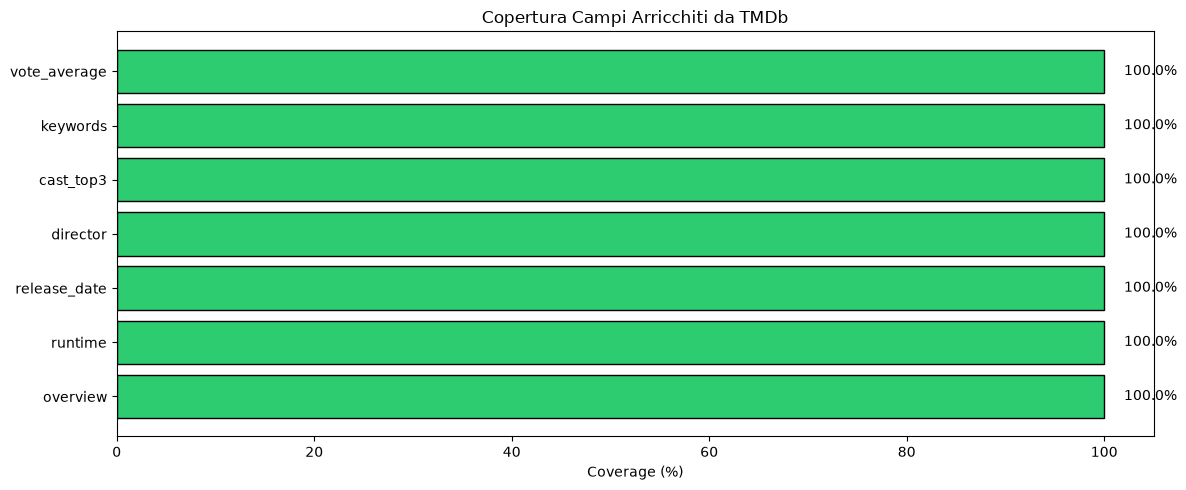

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("\n" + "="*80)
print("CONTROLLI QUALITÀ E AUDIT DATI")
print("="*80)

# Copertura campi arricchiti
coverage_stats = {
    'overview': (df_final_enriched['overview'].notna().sum() / len(df_final_enriched) * 100),
    'runtime': (df_final_enriched['runtime'].notna().sum() / len(df_final_enriched) * 100),
    'release_date': (df_final_enriched['release_date'].notna().sum() / len(df_final_enriched) * 100),
    'director': (df_final_enriched['director'].notna().sum() / len(df_final_enriched) * 100),
    'cast_top5': (df_final_enriched['cast_top5'].notna().sum() / len(df_final_enriched) * 100),
    'cast_characters_top5': (df_final_enriched['cast_characters_top5'].notna().sum() / len(df_final_enriched) * 100),
    'keywords': (df_final_enriched['keywords'].notna().sum() / len(df_final_enriched) * 100),
    'vote_average': (df_final_enriched['vote_average'].notna().sum() / len(df_final_enriched) * 100),
}

print("\nCopertura campi arricchiti (%):")
for field, coverage in sorted(coverage_stats.items(), key=lambda x: x[1], reverse=True):
    bar = '█' * int(coverage / 5) + '░' * (20 - int(coverage / 5))
    print(f"  {field:15} [{bar}] {coverage:5.1f}%")

# Distribuzioni numeriche
print("\nDistribuzioni numeriche:")
if df_final_enriched['runtime'].notna().sum() > 0:
    print(f"  Runtime (min):")
    print(f"    Media: {df_final_enriched['runtime'].mean():.1f} min")
    print(f"    Mediana: {df_final_enriched['runtime'].median():.1f} min")
    print(f"    Range: [{df_final_enriched['runtime'].min()}, {df_final_enriched['runtime'].max()}]")

if df_final_enriched['vote_average'].notna().sum() > 0:
    print(f"  Vote average TMDb:")
    print(f"    Media: {df_final_enriched['vote_average'].mean():.2f}")
    print(f"    Mediana: {df_final_enriched['vote_average'].median():.2f}")

# Audit: film senza metadati critici
missing_audit = {
    'overview_missing': df_final_enriched[df_final_enriched['overview'].isna()],
    'director_missing': df_final_enriched[df_final_enriched['director'].isna()],
    'keywords_missing': df_final_enriched[df_final_enriched['keywords'].isna()],
}

print("\nAudit - Film con gap di metadati:")
for audit_name, audit_df in missing_audit.items():
    print(f"  {audit_name}: {len(audit_df)} film")
    if len(audit_df) > 0 and len(audit_df) <= 5:
        print(f"    Esempi: {', '.join(audit_df['title'].head(3).tolist())}")

# Visualizza copertura con grafico
fig, ax = plt.subplots(figsize=(12, 5))
fields = list(coverage_stats.keys())
coverage_pct = list(coverage_stats.values())
colors = ['#2ecc71' if x > 80 else '#f39c12' if x > 50 else '#e74c3c' for x in coverage_pct]

ax.barh(fields, coverage_pct, color=colors, edgecolor='black')
ax.set_xlabel('Coverage (%)')
ax.set_title('Copertura Campi Arricchiti da TMDb')
ax.set_xlim(0, 105)

for i, (field, pct) in enumerate(zip(fields, coverage_pct)):
    ax.text(pct + 2, i, f'{pct:.1f}%', va='center')

plt.tight_layout()
plt.show()

## 10. Salvataggio Output (CSV/Parquet) e Smoke Test Riproducibili

Esportiamo il dataset finale in formato CSV e Parquet, salviamo log degli errori,
e eseguiamo smoke test con assertion sul dataset.


In [17]:
print("\n" + "="*80)
print("SALVATAGGIO OUTPUT FINALE E SMOKE TEST")
print("="*80)

# Salva in CSV
csv_output_path = DATA_PROCESSED / 'dataset_enriched_movielens_tmdb.csv'
df_final_enriched.to_csv(csv_output_path, index=False)
print(f"✓ Dataset CSV salvato: {csv_output_path}")

# Salva in Parquet (più efficiente per grandi dataset)
try:
    import pyarrow.parquet as pq
    parquet_output_path = DATA_PROCESSED / 'dataset_enriched_movielens_tmdb.parquet'
    df_final_enriched.to_parquet(parquet_output_path, index=False)
    print(f"✓ Dataset Parquet salvato: {parquet_output_path}")
except ImportError:
    print("⚠ PyArrow non disponibile, Parquet saltato")

# Salva log errori dettagliato
if fetch_errors:
    errors_log_path = DATA_PROCESSED / f'fetch_errors_{session_timestamp}.csv'
    errors_df = pd.DataFrame([
        {'tmdbId': tmdb_id, 'error': error_msg}
        for tmdb_id, error_msg in fetch_errors.items()
    ])
    errors_df.to_csv(errors_log_path, index=False)
    print(f"✓ Log errori salvato: {errors_log_path} ({len(errors_df)} errori)")

# Smoke test con assertion
print("\n✓ Esecuzione smoke test...")

# Assert 1: Dataframe non vuoto
assert len(df_final_enriched) > 0, "Dataset finale è vuoto!"
print("  ✓ Dataset non vuoto")

# Assert 2: Chiavi unique per movieId
assert df_final_enriched['movieId'].nunique() == len(df_final_enriched), \
    "Duplicate movieId trovati!"
print("  ✓ movieId sono unique")

# Assert 3: Colonne attese presenti
required_cols = ['movieId', 'tmdbId', 'title', 'overview', 'runtime', 'director']
missing_cols = [c for c in required_cols if c not in df_final_enriched.columns]
assert len(missing_cols) == 0, f"Colonne mancanti: {missing_cols}"
print(f"  ✓ Tutte le colonne richieste presenti")

# Assert 4: Nessuna riga con tutti i campi testuali nulli
fully_empty = df_final_enriched[
    (df_final_enriched['overview'].isna()) & 
    (df_final_enriched['director'].isna()) &
    (df_final_enriched['keywords'].isna())
]
assert len(fully_empty) < len(df_final_enriched) * 0.5, \
    "Troppi film senza metadati critici (>50%)"
print("  ✓ Metadati critici sufficienti")

print("\n✓ Tutti i smoke test passati!")

print("\n" + "="*80)
print("SUMMARY FINALE")
print("="*80)
print(f"Film processati: {len(df_final_enriched)}")
print(f"Output CSV: {csv_output_path}")
print(f"Output Parquet: {parquet_output_path if 'parquet_output_path' in locals() else 'N/A'}")
print(f"Checkpoints: {CHECKPOINTS_DIR}")
print(f"\nProssimi step:")
print("  1. Verificare il dataset con analisi esplorativa")
print("  2. Utilizzare per ranking/reranking test")
print("  3. Integrare con pipeline orchestratore multi-agente")


SALVATAGGIO OUTPUT FINALE E SMOKE TEST
✓ Dataset CSV salvato: ../datasets/processed/dataset_enriched_movielens_tmdb.csv
⚠ PyArrow non disponibile, Parquet saltato

✓ Esecuzione smoke test...
  ✓ Dataset non vuoto
  ✓ movieId sono unique
  ✓ Tutte le colonne richieste presenti
  ✓ Metadati critici sufficienti

✓ Tutti i smoke test passati!

SUMMARY FINALE
Film processati: 50
Output CSV: ../datasets/processed/dataset_enriched_movielens_tmdb.csv
Output Parquet: N/A
Checkpoints: ../datasets/processed/checkpoints

Prossimi step:
  1. Verificare il dataset con analisi esplorativa
  2. Utilizzare per ranking/reranking test
  3. Integrare con pipeline orchestratore multi-agente


In [18]:
# Cleanup: chiudi la sessione TMDb
tmdb_client.close()
logger.info("✓ Sessione TMDb chiusa")

2026-07-28 17:46:00,191 - __main__ - INFO - ✓ Sessione TMDb chiusa
